In [5]:
"""
With doc string in the function, our LLM will know that what are the inputs and 
what are the aruments over here

When our given aruments and input match with the tool, then it know that we need to use this custom Function 

1) LLM + Tool Binding 
2) Custom Functions

We can also combine multiple functions in one tool node 
"""

'\nWith doc string in the function, our LLM will know that what are the inputs and \nwhat are the aruments over here\n\nWhen our given aruments and input match with the tool, then it know that we need to use this custom Function \n\n1) LLM + Tool Binding \n2) Custom Functions\n\nWe can also combine multiple functions in one tool node \n'

In [6]:
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model
from langchain_core.tools import tool

load_dotenv()
llm = ChatGroq(model="openai/gpt-oss-120b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000206977A1950>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000206977A2350>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

### Chat with Tools

In [7]:
from langchain_tavily import TavilySearch

tool1 = TavilySearch(max_results=2)
tool1.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API',
   'score': 0.95386744,
   'raw_content': None,
   'id': '859e22-00'},
  {'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph? | IBM'

In [8]:
## Custom Function 
@tool
def Multiply(a:int, b:int)->int:
    """ Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b
    # Model was not able to differentiate between a and a(int)

In [9]:
tools = [tool1, Multiply]

In [10]:
llm_with_tools = llm.bind_tools(tools)

In [11]:
from typing import Annotated 
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages  

class State(TypedDict):
    messages : Annotated[list, add_messages]  # list of messages in the conversation

In [12]:
## State Graph 
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

# Node definition
def tool_calling_llm(state: State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

## Graph 
builder = StateGraph(State)
# builder.add_node("node_name", function)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # It tool call it routes to tools
    # By Default, If not a tool call routes to END
    tools_condition
)
builder.add_edge("tools", END)

##
graph = builder.compile()


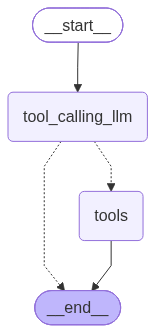

In [13]:
# Visualize Graph 
from IPython.display import Image, display 

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [14]:
response = graph.invoke({"messages":"What is recent AI news"})

In [15]:
response["messages"][-1].content

'{"query": "latest AI news 2024", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.ipsos.com/en-us/artificial-intelligence-key-insights-data-and-tables", "title": "Artificial Intelligence: Key insights, data and tables | Ipsos", "content": "Americans still have a complicated relationship with AI — January 31, 2025\\n Personalization: Putting the ‘i’ in shopping – January 10, 2025\\n Accelerating with Gen AI: 3 client stories to inspire you — December 4, 2024\\n Conversations with AI Part VI: AI-powered moderator bots: Enhancing empathy or eroding connection? — October 17, 2024\\n How social listening can inform better research and development — October 17, 2024\\n Fewer think AI is coming for white collar jobs — October 4, 2024\\n Gen AI use for parents and teens — September 19, 2024\\n Empathy or Emptiness: Unravelling the Impact of AI on Human Connection — September 23, 2024\\n The Ipsos Education Monitor 2024 — August 27, 2024\\n Conversati

In [16]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is recent AI news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_5efd957a-af03-4e55-8605-6f704c358b97)
 Call ID: fc_5efd957a-af03-4e55-8605-6f704c358b97
  Args:
    query: latest AI news 2024
    search_depth: advanced
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news 2024", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.ipsos.com/en-us/artificial-intelligence-key-insights-data-and-tables", "title": "Artificial Intelligence: Key insights, data and tables | Ipsos", "content": "Americans still have a complicated relationship with AI — January 31, 2025\n Personalization: Putting the ‘i’ in shopping – January 10, 2025\n Accelerating with Gen AI: 3 client stories to inspire you — December 4, 2024\n 

In [17]:
response1 = graph.invoke({"messages":"Give me rescent AI News and then Multiply 5 by 10"})

In [18]:
for m in response1["messages"]:
    m.pretty_print()

================================ Human Message =================================

Give me rescent AI News and then Multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_f13c9f0b-08a4-4a30-bbeb-040e29151c1b)
 Call ID: fc_f13c9f0b-08a4-4a30-bbeb-040e29151c1b
  Args:
    query: latest AI news October 2026
    search_depth: advanced
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://tech-insider.org/nasdaq-100-2-trillion-october-wipeout-ai-spending-fears-2026", "title": "Nasdaq 100 AI Spending Fears: $2T October Wipeout [2026]", "content": "Skip to content\n\nLatest news\n\n1. [SpaceX-Tesla Merger: 50% Hurdle, Not a Chip Fab ](\n2. [Florida DOE Breach Hits Up to 4.9M, SSNs at Risk ](\n3. [Redmi K100 Sal

In [19]:
### ReACT Agent Architecture 
## State Graph 
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

# Node definition
def tool_calling_llm(state: State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

## Graph 
builder = StateGraph(State)
# builder.add_node("node_name", function)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # It tool call it routes to tools
    # By Default, If not a tool call routes to END
    tools_condition
)
builder.add_edge("tools", "tool_calling_llm")

##
graph = builder.compile()


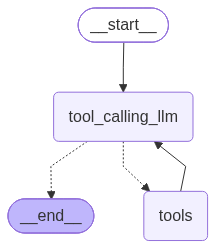

In [20]:
# Visualize Graph 
from IPython.display import Image, display 

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [21]:
response = graph.invoke({"messages":"What is the Latest AI News and what is 2 multiplied by 3?"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the Latest AI News and what is 2 multiplied by 3?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_332ac95f-0e87-4c41-8b35-a16829c623fa)
 Call ID: fc_332ac95f-0e87-4c41-8b35-a16829c623fa
  Args:
    query: latest AI news
    search_depth: advanced
    time_range: day
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.brief.news/ai", "title": "AI News: The Latest Updates and Advancements in AI from Brief", "content": "October 30, 2026\n\nIndian tech giants are spearheading AI integration into core enterprise systems, with TCS's WisdomNext leading the charge in orchestrating AI models and workflows for modernization. Companies like Persistent Systems, Quantiphi, and HC

### Adding Memory in Agentic Graph 

In [22]:
### ReACT Agent Architecture 
## State Graph 
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver() # For every node call it is gonno save the information 

# Node definition
def tool_calling_llm(state: State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

## Graph 
builder = StateGraph(State)
# builder.add_node("node_name", function)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # It tool call it routes to tools
    # By Default, If not a tool call routes to END
    tools_condition
)
builder.add_edge("tools", "tool_calling_llm")

##
graph = builder.compile(checkpointer=memory)

In [23]:
config = {"configurable" :{"thread_id": "1"}}
response = graph.invoke({"messages":"Hi My Name is Naman"}, config=config)
response

{'messages': [HumanMessage(content='Hi My Name is Naman', additional_kwargs={}, response_metadata={}, id='f97abc61-415b-4810-b29d-98d728a97572'),
  AIMessage(content='Hello Naman! 👋 Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hi My Name is Naman". Probably greet them. Maybe ask how can help.'}, response_metadata={'token_usage': {'completion_tokens': 54, 'prompt_tokens': 375, 'total_tokens': 429, 'completion_time': 0.112664377, 'completion_tokens_details': {'reasoning_tokens': 27}, 'prompt_time': 0.062754111, 'prompt_tokens_details': None, 'queue_time': 0.216775979, 'total_time': 0.175418488}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_86dc843b12', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a191b7-fad3-7797-9506-89798d590525-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 375, 'output_tokens': 

In [24]:
response['messages'][-1].content

'Hello Naman! 👋 Nice to meet you. How can I assist you today?'

In [25]:
response1 = graph.invoke({"messages":"What is my Name"}, config=config)
response1['messages'][-1].content

'Your name is Naman.'

### Streaming

In [26]:
from langgraph.checkpoint.memory import MemorySaver
memory =  MemorySaver()

In [27]:
## Node definition 
def superbot(state: State):
    return {"messages":[llm.invoke(state['messages'])]}

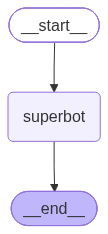

In [28]:
graph = StateGraph(State)

# Adding Node 
graph.add_node("superbot", superbot)

# Adding Edge
graph.add_edge(START, "superbot")
graph.add_edge("superbot", END)

graph_builder = graph.compile(checkpointer = memory)

# Visualize Graph 
from IPython.display import Image, display 
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [29]:
config = {"configurable": {"thread_id" : "1"}}
response2 = graph_builder.invoke({'messages':"Hi, My name is Naman Garg and I love to rule"}, config = config)

In [30]:
response2['messages'][-1].content

'Hello Naman! 👋 Nice to meet you. It sounds like you’ve got a strong sense of confidence—what kind of “ruling” are you interested in? Whether it’s leading a team, mastering a hobby, or just having a bit of fun, I’m happy to chat about it!'

.stream and .astream()

These methords are sync and async methords for streaming back results 

Additional Parameters in streaming modes for graph state 

values: This stream the full state of the graph after each node is called
 
updates: This stream updates to the state of the graph after each node is called c

In [31]:
config = {"configurable": {"thread_id": "1"}}
for chunk in graph_builder.stream({'messages':"Hi, My name is Naman Garg and I love to rule"}, config, stream_mode="updates"):
    print(chunk) ## Here only we are specifically getting a output 

{'superbot': {'messages': [AIMessage(content='Hey again, Naman! 😄\n\nSounds like you’ve got a bold streak—what does “ruling” mean to you? Are you thinking about:\n\n- **Leadership**: Managing a team, starting a project, or taking charge at work/school?  \n- **Gaming**: Being the top player or building an empire in a strategy game?  \n- **Personal mastery**: Dominating a skill, sport, or hobby you love?  \n\nLet me know what you have in mind, and we can dive into tips, strategies, or just chat about what makes a great “ruler” in that arena!', additional_kwargs={'reasoning_content': 'The user repeats the same statement. Possibly they want to continue conversation. The assistant should respond politely, ask clarifying question, maybe discuss leadership or ruling. Should not violate policy. Should be friendly.'}, response_metadata={'token_usage': {'completion_tokens': 177, 'prompt_tokens': 169, 'total_tokens': 346, 'completion_time': 0.366474399, 'completion_tokens_details': {'reasoning_to

In [32]:
for chunk in graph_builder.stream({'messages':"Hi, My name is Naman Garg and I love to rule"}, config, stream_mode="values"):
    print(chunk) # Here we are getting Both 

{'messages': [HumanMessage(content='Hi, My name is Naman Garg and I love to rule', additional_kwargs={}, response_metadata={}, id='4d0a5cca-986a-47e0-b14e-0fe8906f2363'), AIMessage(content='Hello Naman! 👋 Nice to meet you. It sounds like you’ve got a strong sense of confidence—what kind of “ruling” are you interested in? Whether it’s leading a team, mastering a hobby, or just having a bit of fun, I’m happy to chat about it!', additional_kwargs={'reasoning_content': 'The user says: "Hi, My name is Naman Garg and I love to rule". Likely a greeting. They may be introducing themselves. The assistant should respond politely, perhaps ask about their interests. No policy violation. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 122, 'prompt_tokens': 84, 'total_tokens': 206, 'completion_time': 0.253039421, 'completion_tokens_details': {'reasoning_tokens': 51}, 'prompt_time': 0.013772037, 'prompt_tokens_details': None, 'queue_time': 0.211415583, 'total_time': 0.

In [33]:
config = {"configurable": {"thread_id": "3"}}
for chunk in graph_builder.stream({'messages':"Hi, My name is Naman Garg and I love to rule"}, config, stream_mode="updates"):
    print(chunk) ## Here only we are specifically getting a output 

{'superbot': {'messages': [AIMessage(content='Hello Naman! 👋 Nice to meet you. It sounds like you’ve got a confident streak—what kind of “ruling” are you talking about? Are you looking for advice on leadership, a fun role‑playing scenario, or something else entirely? Let me know how I can help!', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hi, My name is Naman Garg and I love to rule". Likely a greeting. We can respond politely, ask about what they want. Possibly ask what they need help with. So a friendly response.'}, response_metadata={'token_usage': {'completion_tokens': 123, 'prompt_tokens': 84, 'total_tokens': 207, 'completion_time': 0.25677646, 'completion_tokens_details': {'reasoning_tokens': 53}, 'prompt_time': 0.003103246, 'prompt_tokens_details': None, 'queue_time': 0.212596384, 'total_time': 0.259879706}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_86dc843b12', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs'

In [34]:
for chunk in graph_builder.stream({'messages':'I also like football'}, config, stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi, My name is Naman Garg and I love to rule', additional_kwargs={}, response_metadata={}, id='810b6377-bace-47de-a1c1-cfc909c2a7f9'), AIMessage(content='Hello Naman! 👋 Nice to meet you. It sounds like you’ve got a confident streak—what kind of “ruling” are you talking about? Are you looking for advice on leadership, a fun role‑playing scenario, or something else entirely? Let me know how I can help!', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hi, My name is Naman Garg and I love to rule". Likely a greeting. We can respond politely, ask about what they want. Possibly ask what they need help with. So a friendly response.'}, response_metadata={'token_usage': {'completion_tokens': 123, 'prompt_tokens': 84, 'total_tokens': 207, 'completion_time': 0.25677646, 'completion_tokens_details': {'reasoning_tokens': 53}, 'prompt_time': 0.003103246, 'prompt_tokens_details': None, 'queue_time': 0.212596384, 'total_time': 0.25987970

In [35]:
config = {"configurable": {"thread_id": "4"}}
async for chunk in graph_builder.astream_events({'messages':"Hi, My name is Naman Garg and I love to rule"}, config, version="v2"):
    print(chunk) ## For getting much more information for debugging and all

{'event': 'on_chain_start', 'data': {'input': {'messages': 'Hi, My name is Naman Garg and I love to rule'}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a191b8-0d8c-70d6-9fd4-e475deeabf70', 'metadata': {'thread_id': '4', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi, My name is Naman Garg and I love to rule', additional_kwargs={}, response_metadata={}, id='f5c39549-9f75-444b-bdf5-5f4a407e7c88')]}}, 'name': 'superbot', 'tags': ['graph:step:1'], 'run_id': '01a191b8-0d8f-7279-8779-f6bab602669f', 'metadata': {'thread_id': '4', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'superbot', 'langgraph_triggers': ('branch:to:superbot',), 'langgraph_path': ('__pregel_pull', 'superbot'), 'langgraph_checkpoint_ns': 'superbot:3a2b8f69-dd85-9eb7-5094-d28acab9ce67'}, 'parent_ids': ['01a191b8-0d8c-70d6-9fd4-e475deeabf70']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages': [[Hum

### Human in the Loop 

In [41]:
from langgraph.types import Command, interrupt
from langchain_core.tools import tool

graph_builder = StateGraph(State)

@tool  # Here we define a function and that function can be converted into a tool 
def human_assistance(query: str) -> str:
    """Request assistance from a human"""
    human_response = interrupt({"query": query})
    return human_response["data"]

In [42]:
tools = [tool1, human_assistance]
llm_with_tools1 = llm.bind_tools(tools)

def chatbot(state: State):
    message = llm_with_tools1.invoke(state['messages'])
    return {"messages":[message]}

graph_builder.add_node("chatbot", chatbot)

tool_node = ToolNode(tools=tools)
graph_builder.add_node("tools", tool_node)

graph_builder.add_conditional_edges(
    "chatbot", 
    tools_condition,
)
graph_builder.add_edge("tools", "chatbot")
graph_builder.add_edge(START, "chatbot")


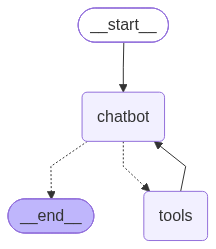

In [43]:
graph = graph_builder.compile(checkpointer = memory)

# Visualize Graph 
from IPython.display import Image, display 
display(Image(graph.get_graph().draw_mermaid_png()))

In [45]:
user_input = "I need a some expert guidance and assistance for building an AI Agent. Could you request assistance for me"
config = {"configurable":{"thread_id":"2"}}
events = graph.stream(
    {'messages': user_input},
    config=config,
    stream_mode="values"
)
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

I need a some expert guidance and assistance for building an AI Agent. Could you request assistance for me
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_1daea9b1-d4ce-4b81-bf86-71812c50c280)
 Call ID: fc_1daea9b1-d4ce-4b81-bf86-71812c50c280
  Args:
    query: User is seeking expert guidance and assistance for building an AI Agent. Please provide detailed help on architecture, tools, best practices, and implementation steps.
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_1daea9b1-d4ce-4b81-bf86-71812c50c280)
 Call ID: fc_1daea9b1-d4ce-4b81-bf86-71812c50c280
  Args:
    query: User is seeking expert guidance and assistance for building an AI Agent. Please provide detailed help on architecture, tools, best practices, and implementation steps.


In [46]:
human_response = (
    "We, the experts are here to help! We'd recommend you check out LangGraph to build your agent."
    "It's much more reliable and extensible than simple autonomous agents."
)

human_command = Command(resume={"data": human_response})
events = graph.stream(human_command, config, stream_mode="values")
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_1daea9b1-d4ce-4b81-bf86-71812c50c280)
 Call ID: fc_1daea9b1-d4ce-4b81-bf86-71812c50c280
  Args:
    query: User is seeking expert guidance and assistance for building an AI Agent. Please provide detailed help on architecture, tools, best practices, and implementation steps.
================================= Tool Message =================================
Name: human_assistance

We, the experts are here to help! We'd recommend you check out LangGraph to build your agent.It's much more reliable and extensible than simple autonomous agents.
================================== Ai Message ==================================

Absolutely—let’s walk through the key pieces you’ll need to design, build, and deploy a robust AI Agent. Below is a practical, end‑to‑end roadmap that you can adapt to the specifics of your use case (e.g., customer‑support bot, research assistant, autonomous 